# KA1 Milestone 1: Exploratory audit of the DataCo dataset
Place `DataCoSupplyChainDataset.csv` in `../data/` and run all cells. Nothing here uses private data; the raw file is git-ignored.

In [9]:
import re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
SEED = 42
np.random.seed(SEED)
PATH = Path("../data/DataCoSupplyChainDataset.csv")
if not PATH.exists():
    PATH = Path("data/DataCoSupplyChainDataset.csv")
df = pd.read_csv(PATH, encoding="latin-1")
print(df.shape)

(180519, 53)


In [17]:
def find(*keys):
    """Return the first column whose lower-cased name contains all keys."""
    for c in df.columns:
        if all(k in c.lower() for k in keys):
            return c
    return None
TARGET = find("late", "risk")
ORDER_ID = next((c for c in df.columns if c.strip().lower() == "order id"), None)
ORDER_DATE = find("order", "date")
print("target:", TARGET, "| order id:", ORDER_ID, "| order date:", ORDER_DATE)
print(df.dtypes.value_counts())

target: Late_delivery_risk | order id: Order Id | order date: order date (DateOrders)
str               24
float64           15
int64             14
datetime64[us]     1
period[Q-DEC]      1
Name: count, dtype: int64


## 1. Unit of analysis

In [19]:
print("rows:", len(df))
if ORDER_ID:
    n_orders = df[ORDER_ID].nunique()
    print("distinct orders:", n_orders, "| rows per order (mean):", round(len(df)/n_orders, 2))

rows: 180519
distinct orders: 65752 | rows per order (mean): 2.75


## 2. Target and drift in the base rate

overall late rate: 0.5483
unparseable dates: 0
            mean   size
_q                     
2015Q1  0.545643  15413
2015Q2  0.543574  15617
2015Q3  0.559381  15712
2015Q4  0.545889  15908
2016Q1  0.551845  15421
2016Q2  0.559050  15453
2016Q3  0.540541  15799
2016Q4  0.551553  15877
2017Q1  0.545184  15470
2017Q2  0.535853  15480
2017Q3  0.551543  15812
2017Q4  0.546161   6434
2018Q1  0.562883   2123


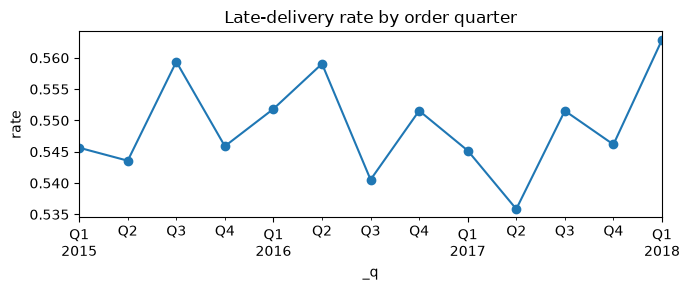

In [12]:
df["_date"] = pd.to_datetime(df[ORDER_DATE], errors="coerce")
df["_q"] = df["_date"].dt.to_period("Q")
print("overall late rate:", round(df[TARGET].mean(), 4))
print("unparseable dates:", int(df["_date"].isna().sum()))
byq = df.groupby("_q")[TARGET].agg(["mean", "size"])
print(byq)
ax = byq["mean"].plot(marker="o", figsize=(7, 3), title="Late-delivery rate by order quarter")
ax.set_ylabel("rate"); plt.tight_layout(); plt.show()

## 3. Missingness

In [13]:
miss = df.isna().mean().sort_values(ascending=False)
print(miss[miss > 0].round(4).to_string())

Product Description    1.0000
Order Zipcode          0.8624
Customer Lname         0.0000
Customer Zipcode       0.0000


## 4. Leakage audit
A column is flagged if its name suggests it is recorded after order placement. Review the list by hand; the keyword screen is only a first pass.

In [14]:
post_keys = ["real", "delivery status", "shipping date", "order status"]
flag = [c for c in df.columns if any(k in c.lower() for k in post_keys) and c != TARGET]
print("post-placement candidates to EXCLUDE:", flag)
tgt_corr = (df.select_dtypes("number").corrwith(df[TARGET]).abs().sort_values(ascending=False).head(10))
print("\nLargest |correlation| with target (inspect for leakage):")
print(tgt_corr.round(3).to_string())

post-placement candidates to EXCLUDE: ['Days for shipping (real)', 'Delivery Status', 'Order Status', 'shipping date (DateOrders)']

Largest |correlation| with target (inspect for leakage):
Late_delivery_risk               1.000
Days for shipping (real)         0.401
Days for shipment (scheduled)    0.369
Order Zipcode                    0.014
Sales per customer               0.004
Order Item Total                 0.004
Benefit per order                0.004
Order Profit Per Order           0.004
Sales                            0.004
Customer Zipcode                 0.003


c:\Users\koush\Desktop\Study Books\PHD\ANLY 530\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\koush\Desktop\Study Books\PHD\ANLY 530\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## 5. Redundancy check: scheduled days versus shipping mode

In [15]:
sched, mode = find("scheduled"), find("shipping", "mode")
if sched and mode:
    print(df.groupby(mode)[sched].nunique())
    print(df.groupby(mode)[TARGET].mean().round(3))

Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


Shipping Mode
First Class       0.953
Same Day          0.457
Second Class      0.766
Standard Class    0.381
Name: Late_delivery_risk, dtype: float64


## 6. Order-placement feature contract (draft)
Columns not flagged above and not identifiers or credentials are candidate predictors; finalize after reviewing the audit.

In [16]:
id_like = [c for c in df.columns if any(k in c.lower() for k in ["email", "password", "fname", "lname", "street", "id", "image", "zipcode"])]
candidates = [c for c in df.columns if c not in flag + id_like + [TARGET, "_date", "_q"]]
print(len(candidates), "candidate columns:")
print(candidates)

31 candidate columns:
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Product Description', 'Product Name', 'Product Price', 'Product Status', 'Shipping Mode']
